# Простейшие нейронные сети на PyTorch

In [1]:
import torch

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use("ggplot")

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

%matplotlib inline

In [2]:
import warnings
warnings.filterwarnings("ignore")

## 1. О данных и бэйзлайнах

Наша главная цель - познакомиться с процессом создания простой нейронной сети и ее обучения.

__Делать всё это мы будем на животных.__ Ежегодно около 7.6 миллионов бедных животных в США оказываются в приютах. Часть из них находит себе новую семью, часть возвращается к старому (бывает, что питомец потерялся и его нашли на улице), а часть погибает. Ужегодно усыпляется около 2.7 млн. собак и кошек.  

Используя датасет с входной информацией (цвет, пол, возраст и т.п.) из одного из приютов, мы попытаемся спрогнозировать что произойдёт с новыми животными, которые попадут в этот приют. Данные, используемые в тетрадке уже были предварительно обработаны и приведены в удобную для построения моделей форму.

In [3]:
animals = pd.read_csv("animals.csv", sep="\t")
animals

,IsDog,Age,HasName,NameLength,NameFreq,MixColor,ColorFreqAsIs,ColorFreqBase,TabbyColor,MixBreed,...,SexStatus_Intact,SexStatus_Unknown,Weekday_0,Weekday_1,Weekday_2,Weekday_3,Weekday_4,Weekday_5,Weekday_6,target
0,1,365.0,1,7,0.000157,1,0.032919,0.463624,0,1,...,0,0,0,0,1,0,0,0,0,Return_to_owner
1,0,365.0,1,5,0.000655,0,0.008092,0.015005,1,1,...,0,0,0,0,0,0,0,0,1,Euthanasia
2,1,730.0,1,6,0.000052,1,0.026293,0.357521,0,1,...,0,0,0,0,0,0,0,1,0,Adoption
3,0,21.0,0,7,0.285871,0,0.000471,0.058418,0,1,...,1,0,0,0,0,0,1,0,0,Transfer
4,1,730.0,0,7,0.285871,0,0.023831,0.075353,0,0,...,0,0,0,0,0,0,1,0,0,Transfer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26724,0,30.0,0,7,0.285871,1,0.034909,0.463624,1,1,...,1,0,0,0,0,1,0,0,0,Transfer
26725,0,90.0,0,7,0.285871,0,0.061778,0.164522,1,1,...,0,0,0,0,1,0,0,0,0,Transfer
26726,1,1460.0,1,4,0.001571,1,0.014587,0.374455,0,1,...,0,0,1,0,0,0,0,0,0,Adoption
26727,0,28.0,0,7,0.285871,0,0.085505,0.199270,0,1,...,1,0,0,0,0,0,0,0,1,Transfer


В датасете находится около 27 тысяч наблюдений и 37 регрессоров. Посмотрим на то как выглядит распределение того, что произошло со зверятами по особям.

In [4]:
animals.target.value_counts()

,count
target,
Adoption,10769
Transfer,9422
Return_to_owner,4786
Euthanasia,1555
Died,197


Видим, что классы несбалансированы. Попробуем оставит четыре класса и объединить класс умерших животных с классом животных, которых усыпили.

In [5]:
animals.loc[animals.target == "Died", "target"] = "Euthanasia"

Закодируем классы.

In [6]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
animals["target"] = le.fit_transform(animals["target"])
animals["target"]

,target
0,2
1,1
2,0
3,3
4,3
...,...
26724,3
26725,3
26726,0
26727,3


In [7]:
animals.target.value_counts()

,count
target,
0,10769
3,9422
2,4786
1,1752


In [8]:
len(animals["target"])

26729

In [9]:
animals.shape

(26729, 38)

Разобьём выборку на тренировочную и тестовую.

In [10]:
X = animals.drop("target", axis=1)
y = animals["target"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape)
print(X_test.shape)

(21383, 37)
(5346, 37)


Прежде, чем учить больших монстров, давайте построим какие-нибудь простые прогнозы, чтобы было с чем сравнить. Давайте построим наивный прогноз, а также обучим линейную регрессию и случайный лес.

### Константный прогноз

Построим константный прогноз, чтобы было с чем сравнивать и прогноз по какой-нибудь модели.

In [12]:
from sklearn.metrics import log_loss

probas = np.array(y_train.value_counts(normalize=True).sort_index())
probas

array([0.40289015, 0.0655661 , 0.17906748, 0.35247627])

In [13]:
# Посмотрим на loss и accuracy на трейне и тесте
loss_train = log_loss(y_train, np.tile(probas, X_train.shape[0]).reshape(-1, 4))
loss_test = log_loss(y_test, np.tile(probas, X_test.shape[0]).reshape(-1, 4))

print(f"Train loss: {round(loss_train, 4)}")
print(f"Test loss: {round(loss_test, 4)}")

accuracy_train = accuracy_score(y_train, np.tile(np.argmax(probas), X_train.shape[0]))
accuracy_test = accuracy_score(y_test, np.tile(np.argmax(probas), X_test.shape[0]))

print(f"Train accuracy: {round(accuracy_train, 4)}")
print(f"Test accuracy: {round(accuracy_test, 4)}")

Train loss: 1.2205
Test loss: 1.2203
Train accuracy: 0.4029
Test accuracy: 0.4029


### Логистическая регрессия

In [14]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()

# Обучим на трейне
logreg.fit(X_train, y_train)

# Посмотрим на loss и accuracy на трейне и тесте
loss_train = log_loss(y_train, logreg.predict_proba(X_train))
loss_test = log_loss(y_test, logreg.predict_proba(X_test))

print(f"Train loss: {round(loss_train, 4)}")
print(f"Test loss: {round(loss_test, 4)}")

accuracy_train = accuracy_score(y_train, logreg.predict(X_train))
accuracy_test = accuracy_score(y_test, logreg.predict(X_test))

print(f"Train accuracy: {round(accuracy_train, 4)}")
print(f"Test accuracy: {round(accuracy_test, 4)}")

Train loss: 1.0647
Test loss: 1.0691
Train accuracy: 0.5527
Test accuracy: 0.5529


### Случайный лес

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=1000, n_jobs=3, max_depth=5)

# Обучим на тесте
rf.fit(X_train, y_train)

# Посмотрим на loss и accuracy на трейне и тесте
loss_train = log_loss(y_train, rf.predict_proba(X_train))
loss_test = log_loss(y_test, rf.predict_proba(X_test))

print(f"Train loss: {round(loss_train, 4)}")
print(f"Test loss: {round(loss_test, 4)}")

accuracy_train = accuracy_score(y_train, rf.predict(X_train))
accuracy_test = accuracy_score(y_test, rf.predict(X_test))

print(f"Train accuracy: {round(accuracy_train, 4)}")
print(f"Test accuracy: {round(accuracy_test, 4)}")

Train loss: 0.8702
Test loss: 0.8866
Train accuracy: 0.6171
Test accuracy: 0.6092


Неплохой результат. Попробуем улучшить его с помощью нейросеток.

## 2. Собираем свою нейросеть

# Пример библиотеки использования верхнеуровневого API

# FAST.AI

In [16]:
from fastai.tabular.all import *

Загрузим датасет, где необходимо предсказать, будет ли человек зарабатывать больше $50K в год.

In [17]:
cat_names = [
    "IsDog",
    "HasName",
    "MixColor",
    "TabbyColor",
    "MixBreed",
    "Domestic",
    "Shorthair",
    "Longhair",
    "Breed_Chihuahua Shorthair Mix",
    "Breed_Domestic Medium Hair Mix",
    "Breed_Domestic Shorthair Mix",
    "Breed_German Shepherd Mix",
    "Breed_Labrador Retriever Mix",
    "Breed_Pit Bull Mix",
    "Breed_Rare",
    "Sex_Female",
    "Sex_Male",
    "Sex_Unknown",
    "SexStatus_Flawed",
    "SexStatus_Intact",
    "SexStatus_Unknown",
    "Weekday_0",
    "Weekday_1",
    "Weekday_2",
    "Weekday_3",
    "Weekday_4",
    "Weekday_5",
    "Weekday_6",
]

In [18]:
cont_names = ["Age", "ColorFreqAsIs", "ColorFreqBase", "Year", "Month", "Day", "Hour"]

In [19]:
splitter = IndexSplitter(X_train.index)
splits = splitter(animals)

In [20]:
tab_data = TabularPandas(
    animals,
    procs=[Categorify, FillMissing, Normalize],
    cat_names=cat_names,
    cont_names=cont_names,
    y_names="target",
    y_block=CategoryBlock,
    splits=splits,
)

In [21]:
dataloader = tab_data.dataloaders(bs=128)

In [22]:
learn = tabular_learner(dataloader, metrics=accuracy)

In [23]:
learn.fit_one_cycle(10)

epoch,train_loss,valid_loss,accuracy,time
0,1.344568,1.293450,0.447131,00:02
1,1.244355,1.097551,0.574241,00:01
2,1.060450,0.939317,0.634008,00:01
3,0.941098,0.897029,0.634757,00:01
4,0.879435,0.878790,0.639059,00:01
5,0.836554,0.858079,0.644952,00:01
6,0.797817,0.854071,0.649348,00:02
7,0.782159,0.851536,0.643923,00:02
8,0.762953,0.845485,0.646495,00:01
9,0.749389,0.844038,0.647758,00:01


# Vanilla PyTorch

In [24]:
INPUT_SIZE = 37
HIDDEN_SIZE = 25
OUTPUT_SIZE = 4
LEARNING_RATE = 1e-3
EPOCHS = 100
BATCH_SIZE = 128

Код представленный выше от fastai значительно упрощает работу с нейронными сетями, но не дает понять, что же происходит на самом деле. Поэтому на первых порах лучше все писать самим. Для этого обратимся к первоисточнику, а именно к оригинальному PyTorch, с которого все началось. И для начала разберем все этапы работы с нейронной сети в упрощенной форме.

In [25]:
!pip install torchmetrics -q

In [26]:
import torch.nn as nn  # содержит функции для реалзации архитектуры нейронных сетей
import torch.nn.functional as F  # содержит различные функции активации и не только
import torch.optim as optim
import torch.utils.data as data_utils

from torchmetrics import Accuracy

Для того чтобы подавать данные в нейронную сеть, создадим `DataLoader`, который предоставляет гибкий API для работы с входными данными.

Создание __DataLoader__ для обучения сети

In [27]:
def create_data_loader(X_train, y_train, X_test, y_test):
    train_tensor = data_utils.TensorDataset(torch.tensor(X_train.astype(np.float32)), torch.tensor(y_train))
    train_loader = data_utils.DataLoader(dataset=train_tensor, batch_size=BATCH_SIZE, shuffle=True)

    test_tensor = data_utils.TensorDataset(torch.tensor(X_test.astype(np.float32)), torch.tensor(y_test))
    test_loader = data_utils.DataLoader(dataset=test_tensor, batch_size=BATCH_SIZE, shuffle=False)

    return train_loader, test_loader

In [28]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
sc.fit(X_train.values)

StandardScaler()

In [29]:
train_loader, test_loader = create_data_loader(X_train.values, y_train.values, X_test.values, y_test.values)

__Архитектура модели__

Архитектуру нейронной сети в PyTorch можно описать нескольками способами, в дальнейшем мы рассмотрим их более подробно. Сейчас предлагается сделать это используя `Sequential`.
`Sequential` -- это последовательный способ объявления каждой компоненты архитектуры нейронной сети.

In [30]:
def build_simple_model():
    # Sequential - наборс последовательных слоёв
    model = nn.Sequential(
        # Добавляем в нашу модель первый слой из 25 нейронов
        nn.Linear(in_features=INPUT_SIZE, out_features=HIDDEN_SIZE),
        nn.Sigmoid(),

        # Добавляем ещё один слой из 25 нейронов
        nn.Linear(in_features=HIDDEN_SIZE, out_features=HIDDEN_SIZE),
        nn.Sigmoid(),

        # Выходной вектор на количество классов, получаем с помощью такого же линейного приеобразования,
        # как и предыдущие слои, но уже на нужное количество выходных нейронов (т.е. классов)
        nn.Linear(in_features=HIDDEN_SIZE, out_features=OUTPUT_SIZE),
        nn.Softmax(),
    )

    return model

In [31]:
model = build_simple_model()

In [32]:
print(model)

Sequential(
  (0): Linear(in_features=37, out_features=25, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=25, out_features=25, bias=True)
  (3): Sigmoid()
  (4): Linear(in_features=25, out_features=4, bias=True)
  (5): Softmax(dim=None)
)


Обратите внимание, что последняя функция в в архитектуре сети -- это `Softmax`. Напомним, что `Softamx` используется для задачи классификации, чтобы получить значение увернности сети по каждому классу. Получается вектор на заданное количество классов, где наибольшее значение в какой-либо координате говорит о том, что сеть считает данный класс наиболее подходящим для данного наблюдения.

Отлично! Только что мы собрали свою первую нейросеть со скрытым слоем. Осталось ее обучить.

__Обучение модели__

Перед тем как обучать нашу нейросеть, нужно задать параметры обучения.
- Во-первых, метод оптимизации.
- Во-вторых, функцию потерь.
- В-третьих, парочку метрик, на которые нам хотелось бы смотреть в процессе обучения.  

In [33]:
# Оптимизатор
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Функция потерь
criterion = nn.CrossEntropyLoss()

# Метрика
accuracy = Accuracy(task="multiclass", num_classes=4)

# softmax = nn.Softmax()

Создадим массивы, куда будем складывать значение целевой функции на обучающей и валиационной выборках, а также точность.

Ниже представлен код __обучения__ сети. Нужно обратить внимание на несколько моментов:
1. Обучение ведется в течение нескольких эпох -- что значит несколько проходов по выборке.
2. `train_loader` позволяет итеративно проходится по выборке и на каждой итерации получать батч заранее заданного размера.
3. На каждом шаге обнуляем градиенты `optimizer.zero_grad()`, чтобы не накапливать их, тем самым неккоректно обновлять веса.
4. Вызывать явно `loss.backward()` для вычисления градиентов.
5. Вызывать явно `optimizer.step()` для обновления весов.

In [34]:
train_loss_values = []
train_accuracy_values = []
valid_loss_values = []
valid_accuracy = []

def run_train():
    step = 0

    # Epochs
    for epoch in range(EPOCHS):
        running_loss = []
        running_acc = []
        model.train()
        for features, label in train_loader:
            # Reset gradients
            optimizer.zero_grad()

            output = model(features)
            # Calculate error and backpropagate
            loss = criterion(output, label)
            loss.backward()

            # softmax_output = softmax(output)
            acc = accuracy(output, label).item()

            # Update weights with gradients
            optimizer.step()

            running_loss.append(loss.item())
            running_acc.append(acc)

            step += 1

        train_loss_values.append(np.mean(running_loss))
        train_accuracy_values.append(np.mean(running_acc))
        if epoch % 20 == 0:
            print(f"EPOCH {epoch} : train_loss: {train_loss_values[-1]} train_acc: {train_accuracy_values[-1]}")

        # Run validation
        running_loss = []
        running_acc = []
        model.eval()
        for features, label in test_loader:
            output = model(features)
            # Calculate error and backpropagate
            loss = criterion(output, label)

            # softmax_output = softmax(output)
            acc = accuracy(output, label).item()

            running_loss.append(loss.item())
            running_acc.append(acc)

        valid_loss_values.append(np.mean(running_loss))
        valid_accuracy.append(np.mean(running_acc))
        if epoch % 20 == 0:
            print(f"EPOCH {epoch} : valid_loss: {valid_loss_values[-1]} valid_acc: {valid_accuracy[-1]}")

    return train_loss_values, train_accuracy_values, valid_loss_values, valid_accuracy

In [35]:
train_loss_values, train_accuracy_values, valid_loss_values, valid_accuracy_values = run_train()

EPOCH 0 : train_loss: 1.3137458193869818 train_acc: 0.4017790710287435
EPOCH 0 : valid_loss: 1.2919578580629258 valid_acc: 0.40283345466568354
EPOCH 20 : train_loss: 1.1757217986243111 train_acc: 0.5484760311387834
EPOCH 20 : valid_loss: 1.2166953569366818 valid_acc: 0.4836309523809524
EPOCH 40 : train_loss: 1.1842774287575768 train_acc: 0.520262011105106
EPOCH 40 : valid_loss: 1.186057374590919 valid_acc: 0.52030187135651
EPOCH 60 : train_loss: 1.192616731638 train_acc: 0.5170267327200799
EPOCH 60 : valid_loss: 1.1910442482857477 valid_acc: 0.5187150750841413
EPOCH 80 : train_loss: 1.1119893654471351 train_acc: 0.6223360438432012
EPOCH 80 : valid_loss: 1.1163678680147444 valid_acc: 0.6147086066859109


 Посмотрим на динамику ошибки и значение точности нашей модели во времени.

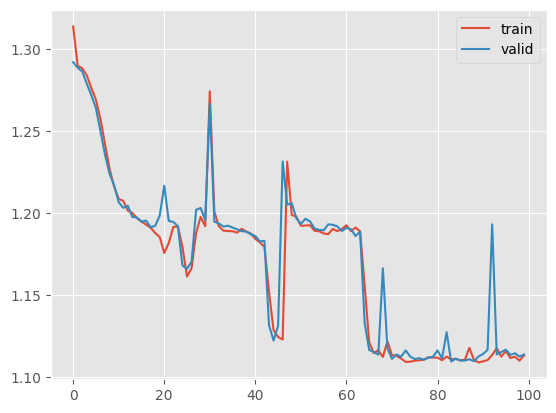

In [36]:
start = 0
plt.plot(train_loss_values[start:], label="train")
plt.plot(valid_loss_values[start:], label="valid")
plt.legend()

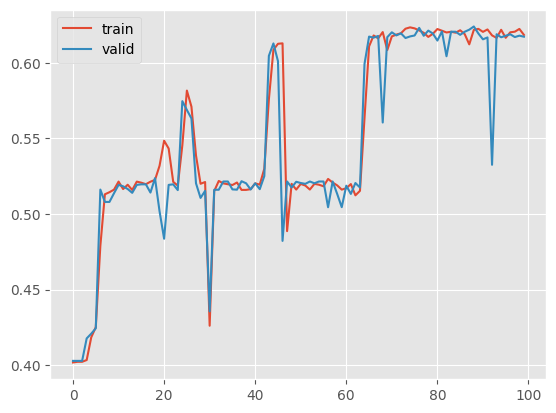

In [37]:
start = 0
plt.plot(train_accuracy_values[start:], label="train")
plt.plot(valid_accuracy_values[start:], label="valid")
plt.legend()

Сохраним модель. Файл может иметь два расширения, как .pt, так и .pth.

In [38]:
torch.save(model, "simple_nn.pth")

Теперь загрузим сохраненную модель и посмотрим на ее предсказания. Важно! Когда идет этап inference модели, то нужно явно вызвать `model.eval()`, так как в случае если есть droupout или batch norm, то они не дложны работать как в процессе обучения, иначе они продолжат обучаться.

In [39]:
model = torch.load("simple_nn.pth", weights_only=False)
model.eval()

Sequential(
  (0): Linear(in_features=37, out_features=25, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=25, out_features=25, bias=True)
  (3): Sigmoid()
  (4): Linear(in_features=25, out_features=4, bias=True)
  (5): Softmax(dim=None)
)

In [40]:
# Выход модели (вероятность) на тестовой выборке
with torch.no_grad():
    test_scores = model(torch.tensor(X_test.values.astype(np.float32)))
print(accuracy(test_scores, torch.tensor(y_test.values.astype(np.int32))).item())
print(test_scores.numpy())

0.6172839403152466
[[9.9387723e-01 2.0234071e-07 2.2658149e-03 3.8567923e-03]
 [9.9449086e-01 1.8914504e-07 2.1407104e-03 3.3681376e-03]
 [1.2875357e-02 3.9579311e-07 1.5585141e-03 9.8556572e-01]
 ...
 [9.9451929e-01 1.8851996e-07 2.1347490e-03 3.3458234e-03]
 [9.9033010e-01 2.6822232e-07 2.8709942e-03 6.7986213e-03]
 [9.9451524e-01 1.8860820e-07 2.1355895e-03 3.3489671e-03]]


In [41]:
log_loss(y_test, test_scores.numpy())

2.331297815822661

In [42]:
# Предсказание классов на тестовой выборке
with torch.no_grad():
    test_scores = model(torch.tensor(X_test.values.astype(np.float32)))
predicted_classes = torch.argmax(test_scores, dim=1)
print(predicted_classes)
print(round(accuracy_score(y_test, predicted_classes), 4))

tensor([0, 0, 3,  ..., 0, 0, 0])
0.6173
